# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [2]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# cargar archivos
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [4]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [5]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [6]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [7]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [8]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [9]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [10]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [11]:
print("--- Nulos en USERS (Cantidad) ---")
print(users.isnull().sum())

print("\n--- Nulos en USERS (Proporción %) ---")
print(users.isnull().mean() * 100)

--- Nulos en USERS (Cantidad) ---
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

--- Nulos en USERS (Proporción %) ---
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [12]:
print("--- Nulos en USAGE (Cantidad) ---")
print(usage.isnull().sum())

print("\n--- Nulos en USAGE (Proporción %) ---")
print(usage.isnull().mean() * 100)

--- Nulos en USAGE (Cantidad) ---
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

--- Nulos en USAGE (Proporción %) ---
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64


✍️ **Comentario**: **Diagnóstico de valores nulos**

En el dataset `users` se identificaron las siguientes columnas con valores faltantes:

- `city`: 469 valores nulos (11,725 %). Se recomienda conservarlos como nulos, ya que no es posible determinar la ciudad real sin información adicional.
- `churn_date`: 3.534 valores nulos (88,35 %). No se recomienda eliminar esta columna, porque la ausencia de una fecha de cancelación puede indicar que el cliente continúa activo. Es necesario conservarla para analizar la cancelación de clientes.

En el dataset `usage` se identificaron:

- `date`: 50 valores nulos (0,125 %). Se recomienda conservar los registros inicialmente y evaluar si la ausencia de fecha afecta el análisis temporal.
- `duration`: 22.076 valores nulos (55,19 %).
- `length`: 17.896 valores nulos (44,74 %).

Los valores faltantes de `duration` y `length` deben analizarse según el tipo de actividad (`call` o `text`), ya que pueden representar valores no aplicables en lugar de información perdida.

**Conclusión:** No se recomienda eliminar registros de forma generalizada. Cada columna requiere un tratamiento según su significado y relevancia para el análisis.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [13]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


La columna `user_id` presenta identificadores entre 10000 y 13999. La columna `age` muestra edades entre 18 y 79 años, con un promedio de 48.14 años. En el resultado actual no se observan edades negativas ni valores sentinel. Sin embargo, es necesario confirmar si los datos ya fueron limpiados anteriormente.

In [14]:
# Explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


**Análisis de las columnas numéricas de `usage`:**

- Las columnas `id` y `user_id` contienen identificadores numéricos.
- La columna `duration` presenta 17.924 valores válidos, una duración promedio de 5.20 minutos y un máximo de 120 minutos.
- La columna `length` presenta 22.104 valores válidos, una longitud promedio de 52.13 caracteres y un máximo de 1.490 caracteres.
- Los valores nulos en `duration` y `length` pueden estar relacionados con el tipo de actividad, ya que las llamadas registran duración y los mensajes registran longitud.
- Los valores máximos de duración y longitud deben revisarse posteriormente para determinar si representan valores atípicos.

In [15]:
# explorar columnas categóricas de users
print("--- Valores únicos en city ---")
print(users['city'].value_counts(dropna=False))

print("\n--- Valores únicos en plan ---")
print(users['plan'].value_counts(dropna=False))


--- Valores únicos en city ---
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

--- Valores únicos en plan ---
Basico     2595
Premium    1405
Name: plan, dtype: int64


- La columna `city` contiene nombres de ciudades principales, pero incluye valores nulos (NaN) y el sentinel ? (96 registros) que deben limpiarse.
- La columna `plan` solo contiene dos categorías válidas ("Basico" y "Premium") sin anomalías.

In [16]:
# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

La columna `type` contiene dos categorías válidas: `text` (22.092 registros) y `call` (17.908 registros). No se identifican valores nulos ni categorías inconsistentes. Por lo tanto, esta columna no requiere limpieza.


**Valores inválidos o sentinels**

**¿En qué columnas encontraste valores inválidos o sentinels?**

En la columna `city` se identificaron 96 registros con el símbolo `?`, que representa información desconocida. En la columna `age`, el resumen estadístico actual muestra edades entre 18 y 79 años, por lo que no se observan valores inválidos en este resultado. Se debe verificar si el valor sentinel `-999` fue corregido previamente.

**¿Qué acción tomarías?**

Reemplazar los símbolos `?` de la columna `city` por valores nulos (`pd.NA`). Si se confirma la presencia de `-999` en los datos originales de `age`, reemplazarlo por la mediana de las edades válidas. Estas acciones se realizarán durante la limpieza de datos.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [17]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [18]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [19]:
# Revisar los años presentes en `reg_date` de users
print("--- Años en reg_date (users) ---")
print(users['reg_date'].dt.year.value_counts(dropna=False))

--- Años en reg_date (users) ---
2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64


En la columna `reg_date` se identificaron registros de los años 2022, 2023 y 2024, además de 40 registros correspondientes a 2026.

Estos 40 registros están fuera del período de análisis, que finaliza en 2024, por lo que se consideran fechas inválidas.

Se recomienda convertir estas fechas fuera de rango en valores nulos (`NaT`) durante la etapa de limpieza, conservando los demás datos de los usuarios.

In [20]:
# Revisar los años presentes en `date` de usage
print("\n--- Años en date (usage) ---")
print(usage['date'].dt.year.value_counts(dropna=False))


--- Años en date (usage) ---
2024.0    39950
NaN          50
Name: date, dtype: int64


En la columna `date` del dataset `usage` se identificaron 39.950 registros correspondientes al año 2024 y 50 registros con fechas faltantes (`NaN`).

No se encontraron años fuera del período de análisis entre las fechas válidas.

Se recomienda conservar inicialmente los registros sin fecha y evaluar su tratamiento durante la limpieza, ya que podrían contener información útil sobre llamadas y mensajes.

**Fechas fuera de rango**

**¿Aparecen años imposibles?**

Sí. En la columna `reg_date` de `users` se identificaron 40 registros correspondientes al año 2026, fuera del período histórico que finaliza en 2024.

En la columna `date` de `usage` se encontraron 50 fechas faltantes, pero no se identificaron años fuera de rango entre las fechas válidas.

**¿Qué harías con ellas?**

Se recomienda convertir las 40 fechas de registro fuera de rango en valores nulos (`NaT`), conservando los demás datos de los usuarios.

Los 50 registros de uso sin fecha se evaluarán durante la limpieza para determinar si pueden conservarse en análisis que no requieren información temporal.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [21]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [22]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].value_counts(dropna=False))

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64


In [23]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print(users['reg_date'].dt.year.value_counts(dropna=False))

2024.0    1330
2023.0    1316
2022.0    1314
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [24]:
# Verificación MAR en usage para duration
print(pd.crosstab(usage['type'], usage['duration'].isna()))

duration  False  True 
type                  
call      17908      0
text         16  22076


In [25]:
# Verificación MAR en usage para length
print(pd.crosstab(usage['type'], usage['length'].isna()))


length  False  True 
type                
call       12  17896
text    22092      0


**Diagnóstico de valores nulos en `duration` y `length`**

Los resultados muestran que los valores nulos dependen principalmente del tipo de actividad (`type`).

En `duration`, las 17.908 llamadas tienen una duración registrada, mientras que 22.076 mensajes presentan valores nulos. Sin embargo, existen 16 mensajes con duración registrada.

En `length`, los 22.092 mensajes tienen una longitud registrada, mientras que 17.896 llamadas presentan valores nulos. También se identificaron 12 llamadas con longitud registrada.

Esto indica que los valores faltantes están asociados al tipo de actividad, por lo que pueden considerarse estructurales y compatibles con el mecanismo MAR solicitado en el ejercicio.

**Decisión:** conservar los valores nulos de `duration` y `length` sin imputarlos, ya que representan principalmente campos que no corresponden al tipo de actividad. Las excepciones identificadas deberán tenerse en cuenta al interpretar los datos.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [26]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) # conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) # conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',
    'is_call': 'sum',
    'duration': 'sum'
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})

# observar resultado
display(usage_agg.head(3))

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [28]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


In [29]:
print("Total de usuarios:", len(user_profile))

print("\nValores nulos en métricas de uso:")
print(user_profile[
    ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
].isna().sum())

Total de usuarios: 4000

Valores nulos en métricas de uso:
cant_mensajes           1
cant_llamadas           1
cant_minutos_llamada    1
dtype: int64


In [30]:
columnas_uso = [
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

user_profile[columnas_uso] = user_profile[columnas_uso].fillna(0)

print(user_profile[columnas_uso].isna().sum())

cant_mensajes           0
cant_llamadas           0
cant_minutos_llamada    0
dtype: int64


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [31]:

# Resumen estadístico de las columnas numéricas
user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.136000,5.523000,4.477000,23.311225
std,17.689919,2.359738,2.145139,18.169564
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.107500
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.412500
max,79.000000,17.000000,15.000000,155.690000


In [32]:
# Distribución porcentual del tipo de plan
print(user_profile['plan'].value_counts(normalize=True) * 100)

Basico     64.875
Premium    35.125
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

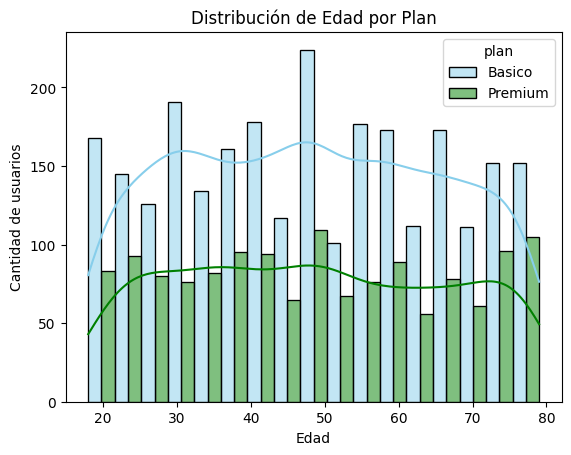

In [33]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], kde=True, multiple='dodge')
plt.title('Distribución de Edad por Plan')
plt.xlabel('Edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

La distribución de edades es aproximadamente uniforme, con usuarios entre 18 y 79 años y sin una asimetría marcada hacia la derecha o izquierda.

Los planes Básico y Premium presentan patrones de edad similares, sin diferencias importantes en la concentración por grupos etarios.

El plan Básico registra una mayor cantidad de usuarios en casi todas las edades, debido a su mayor participación en la base de clientes (64.88% frente al 35.12% del plan Premium).

**Conclusión:** No se observa una relación clara entre la edad y el tipo de plan contratado. Para confirmar esta observación sería necesario comparar las proporciones por edad de ambos planes.

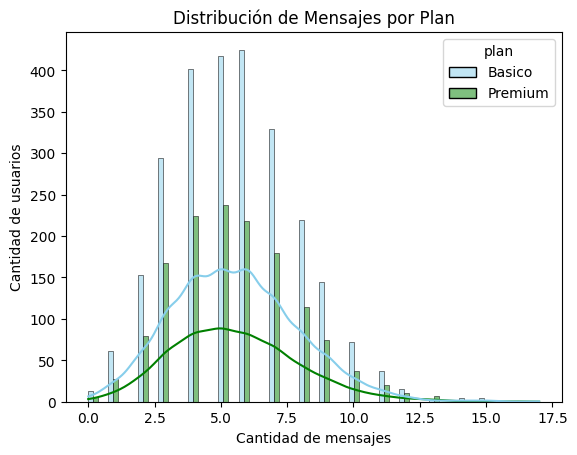

In [34]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], kde=True, multiple='dodge')
plt.title('Distribución de Mensajes por Plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()


La distribución de mensajes presenta una forma aproximadamente simétrica, con una mayor concentración de usuarios entre 3 y 7 mensajes.

El plan Básico registra una mayor cantidad de usuarios que el Premium, debido a que tiene más clientes en total.

Ambos planes muestran patrones de uso similares, sin diferencias importantes en la cantidad de mensajes enviados.

**Conclusión:** No se observa una diferencia clara en el comportamiento de mensajería entre los usuarios de los planes Básico y Premium.

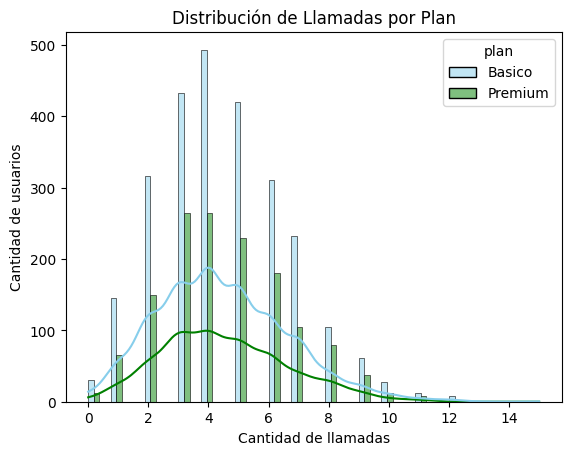

In [35]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], kde=True, multiple='dodge')
plt.title('Distribución de Llamadas por Plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()

La distribución de llamadas presenta una ligera asimetría hacia la derecha, con una mayor concentración de usuarios entre 2 y 6 llamadas.

El plan Básico registra una mayor cantidad de usuarios en casi todos los valores, debido a que tiene más clientes que el plan Premium.

Ambos planes muestran patrones de uso similares, aunque existen algunos usuarios que realizan un número considerablemente mayor de llamadas.

**Conclusión:** No se observan diferencias importantes en la distribución de llamadas entre ambos planes. La mayoría de los usuarios mantiene un nivel de actividad moderado.

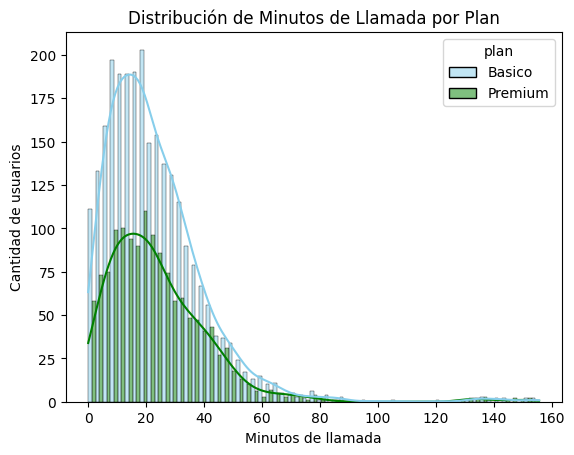

In [36]:
# Histograma para visualizar los minutos de llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], kde=True, multiple='dodge')
plt.title('Distribución de Minutos de Llamada por Plan')
plt.xlabel('Minutos de llamada')
plt.ylabel('Cantidad de usuarios')
plt.show()

La distribución de minutos de llamada presenta una clara asimetría hacia la derecha. La mayoría de los usuarios acumula entre 5 y 40 minutos de llamadas, mientras que un grupo reducido registra valores superiores a 100 minutos.

El plan Básico presenta una mayor cantidad de usuarios debido a su mayor participación en la base de clientes.

Ambos planes muestran patrones de consumo similares, con una concentración en los valores bajos y una disminución progresiva hacia los valores altos.

**Conclusión:** La mayoría de los clientes mantiene un consumo moderado de minutos de llamada. Se identifican algunos valores extremos que conviene analizar para determinar si corresponden a usuarios de alto consumo.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

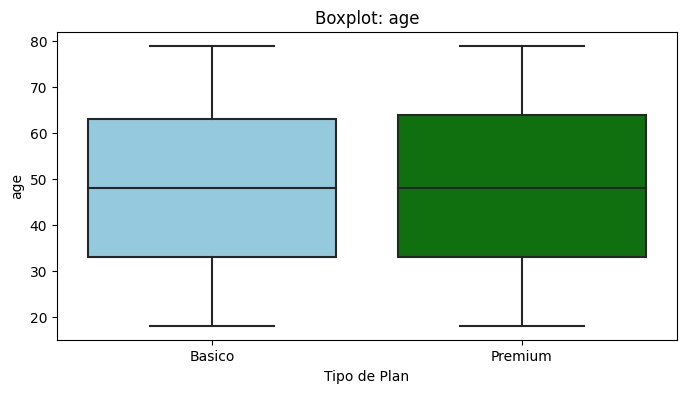

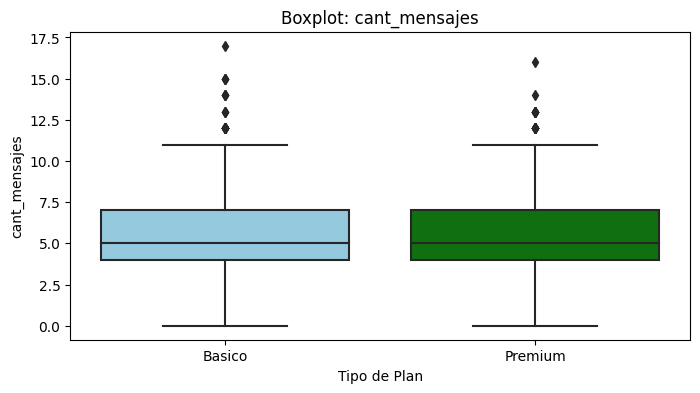

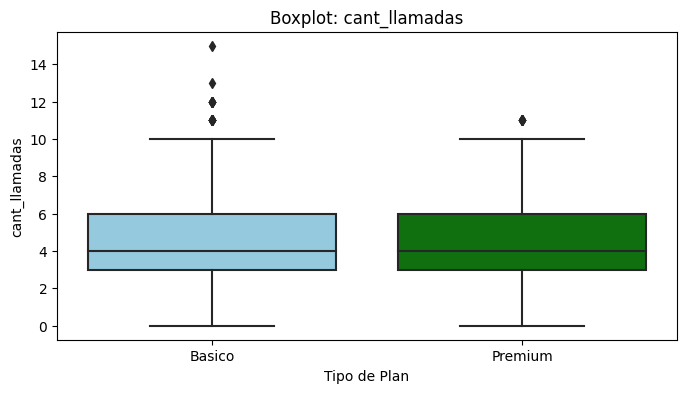

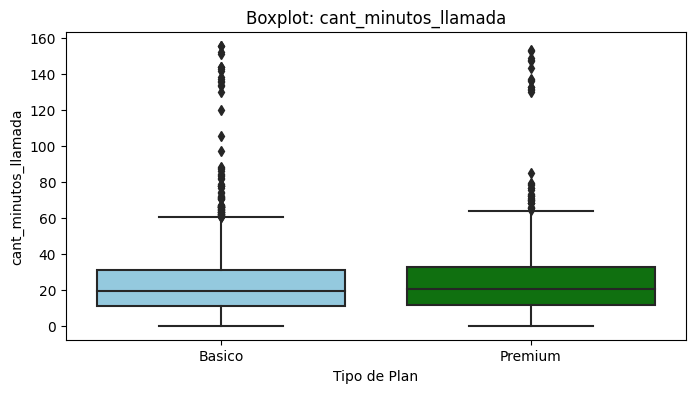

In [37]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x='plan', y=col, palette=['skyblue', 'green'])
    plt.title(f'Boxplot: {col}')
    plt.xlabel('Tipo de Plan')
    plt.ylabel(col)
    plt.show()

💡 **Insights:**

- **Age:** No presenta outliers. Las edades están entre 18 y 79 años, dentro de un rango válido.
- **cant_mensajes:** Presenta outliers superiores a 11.5 mensajes, con un máximo de 17.
- **cant_llamadas:** Presenta outliers superiores a 10.5 llamadas, con un máximo de 15.
- **cant_minutos_llamada:** Presenta outliers superiores a 61.86 minutos, con un máximo de 155.69.


In [38]:
## Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    print(f"Columna: {col} | Q1: {Q1} | Q3: {Q3} | IQR: {IQR} | Límite Superior: {limite_superior}")

Columna: cant_mensajes | Q1: 4.0 | Q3: 7.0 | IQR: 3.0 | Límite Superior: 11.5
Columna: cant_llamadas | Q1: 3.0 | Q3: 6.0 | IQR: 3.0 | Límite Superior: 10.5
Columna: cant_minutos_llamada | Q1: 11.1075 | Q3: 31.4125 | IQR: 20.305 | Límite Superior: 61.870000000000005


In [39]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000


💡 **Insights:**

- **cant_mensajes:** Se recomienda mantener los outliers porque pueden representar usuarios con mayor actividad de mensajería y no necesariamente errores.

- **cant_llamadas:** Se recomienda mantener los outliers porque pueden corresponder a usuarios que realizan más llamadas de lo habitual.

- **cant_minutos_llamada:** Se recomienda mantener provisionalmente los outliers porque pueden representar usuarios con un consumo elevado de minutos. Es conveniente verificar los valores extremos antes de decidir eliminarlos.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [40]:
# Clasificar clientes según su uso
def clasificar_uso(row):
    llamadas = row['cant_llamadas']
    mensajes = row['cant_mensajes']

    if llamadas < 5 and mensajes < 5:
        return 'Bajo uso'
    elif llamadas < 10 and mensajes < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)

# Verificar resultados
print(user_profile['grupo_uso'].value_counts())


Uso medio    2943
Bajo uso      779
Alto uso      278
Name: grupo_uso, dtype: int64


In [41]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [45]:
# Crear columna grupo_edad
def clasificar_edad(age):
    if age < 30:
        return 'Joven'
    elif age < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile['age'].apply(clasificar_edad)


In [46]:
# Verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


In [47]:
print(user_profile['grupo_edad'].value_counts())

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

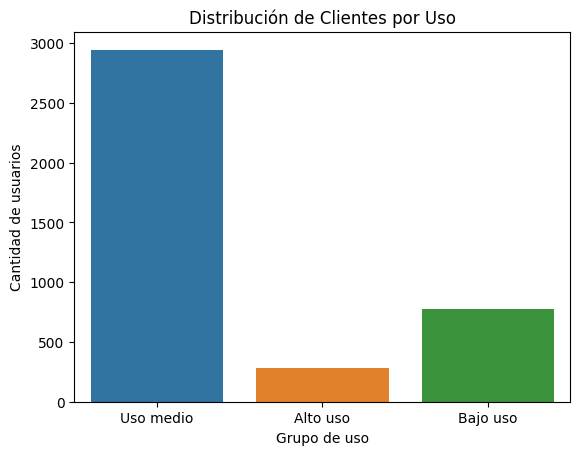

In [49]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso')

plt.title('Distribución de Clientes por Uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()


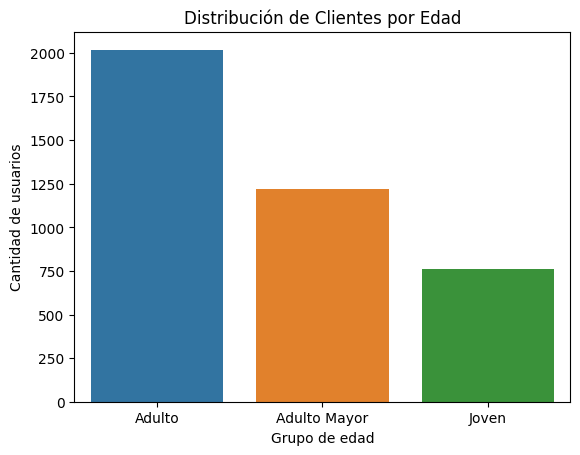

In [50]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad')

plt.title('Distribución de Clientes por Edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**


### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

- Se identificaron valores nulos en las variables de uso `cant_mensajes`, `cant_llamadas` y `cant_minutos_llamada`, con un registro faltante en cada columna. Estos valores se reemplazaron por cero para permitir el análisis de los 4.000 usuarios.

- Se detectaron valores atípicos en mensajes, llamadas y minutos de llamada. Estos registros representan comportamientos de uso superiores a los habituales y deben analizarse antes de decidir su eliminación, ya que podrían corresponder a clientes con consumo elevado.


🔍 **Segmentos por Edad**
- La segmentación por edad muestra que el grupo Adulto (30 a 59 años) representa el 50,45 % de los clientes (2.018 usuarios), seguido de Adulto Mayor (60 años o más) con el 30,55 % (1.222 usuarios) y Joven (menores de 30 años) con el 19 % (760 usuarios).

- El segmento Adulto concentra la mayor cantidad de clientes, por lo que constituye un grupo prioritario para analizar oportunidades comerciales y estrategias de fidelización. Sin embargo, se requiere evaluar su consumo y rentabilidad antes de determinar qué segmento genera mayor valor para la empresa.

📊 **Segmentos por Nivel de Uso**
- La segmentación por nivel de uso muestra que el 73,58 % de los clientes (2.943 usuarios) pertenece al grupo Uso medio, seguido del 19,48 % (779 usuarios) con Bajo uso y el 6,95 % (278 usuarios) con Alto uso. Esto demuestra que la mayoría de los clientes presenta un consumo moderado de llamadas y mensajes.

- El segmento de Uso medio representa la principal oportunidad comercial por su tamaño, mientras que los clientes de Alto uso podrían beneficiarse de planes con mayores beneficios y capacidad. El grupo de Bajo uso podría ser atendido mediante planes económicos y estrategias de fidelización para incentivar su consumo.

➡️ Esto sugiere que ConnectaTel debería priorizar estrategias comerciales dirigidas al segmento de Uso medio, que representa el 73,58 % de sus clientes. Asimismo, existe una oportunidad de ofrecer planes diferenciados para usuarios de Alto uso y alternativas económicas para clientes de Bajo uso. La personalización de los planes podría contribuir a mejorar la satisfacción, fidelización y retención de clientes.

💡 **Recomendaciones**
- **Optimización de planes comerciales:** Se recomienda desarrollar ofertas diferenciadas según el nivel de consumo. Para los clientes de Uso medio (73,58 %), ofrecer beneficios adicionales que incentiven su permanencia y posible migración a planes superiores. Para los usuarios de Alto uso (6,95 %), evaluar planes con mayor capacidad de llamadas y mensajes. Para los clientes de Bajo uso (19,48 %), considerar alternativas económicas adaptadas a sus necesidades.

- **Fidelización y análisis del comportamiento:** Se recomienda implementar estrategias de retención dirigidas a los distintos segmentos de edad y consumo. Asimismo, analizar los usuarios con valores atípicos para identificar necesidades específicas y oportunidades comerciales, evitando eliminar registros que podrían representar comportamientos legítimos de consumo elevado. Antes de implementar cambios, se recomienda evaluar la rentabilidad y la tasa de abandono de cada segmento.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`